In [1]:
!pip install python-dotenv sqlalchemy psycopg2-binary

### Database Connections to PostgreSQL

In [4]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy import inspect

load_dotenv()
engine = create_engine(f"postgresql://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}")


### Database Table check

In [5]:
inspector = inspect(engine)
tables = inspector.get_table_names()
for table in tables:
    print(f"Table: {table}")




Table: pos_sales_data
Table: sales
Table: students
Table: marks
Table: sub_marks
Table: product_tbl
Table: order_tbl


### Load the table

In [6]:
df = pd.read_sql_table("sales", engine, schema="public")
df.head()

,Date,Transaction ID,Invoice No,Invoice type,Customer Name,Customer ID,Customer Type,Barcode,Product Name,Product Category,...,Invoice Value,Discount,Sales Amount,Sales VAT,Sales Return,Credited Amount,Payment Method,Bank Name,Remarks,Month Name
0,2025-03-09,TXN100001,INV10001,Cash Sale,M/S Nazma Store Store,CUST0106,Online,8834993708224,Wall Clock 2,Gift Items,...,7372.68,1105.90,6266.78,0.00,0.0,6266.78,Bkash,None,Advance Payment,March
1,2025-05-20,TXN100002,INV10002,Credit Sale,M/S Mohammadia Trading Store,CUST0155,Wholesale,8817094232227,Photo Frame 3,Gift Items,...,51918.40,0.00,51918.40,0.00,0.0,0.00,Cash,None,Regular Sale,May
2,2025-09-11,TXN100003,INV10003,Credit Sale,M/S Sajid & Brothers Store,CUST0195,Wholesale,8864775758589,Gift Box 2,Gift Items,...,220.45,11.02,209.43,0.00,0.0,0.00,Cash,None,Special Discount,September
3,2025-06-14,TXN100004,INV10004,Cash Sale,M/S Kagotia Crockeries Store,CUST0119,Online,8830160360945,Fan 2,Electronics,...,6123.60,122.47,6001.13,300.06,0.0,0.00,Cash,None,Wholesale Order,June
4,2025-01-16,TXN100005,INV10005,Corporate Order,M/S Daniel Wagner Construction,CUST0058,Corporate,8879637317274,Electric Kettle 4,Electronics,...,4723.06,0.00,4723.06,236.15,0.0,1487.76,Cash,None,Repeat Customer,January


In [7]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

### Dataset Information

In [8]:
# 1.1 Basic shape & column types
print("Rows :", df.shape[0])
print("Cols :", df.shape[1])
print("\n--- dtypes ---")
print(df.dtypes)

# 1.2 First & last rows
display(df.head(3))
display(df.tail(3))

# 1.3 Numeric summary
numeric_cols = ['Purchase Value','Invoice Value','Discount','Sales Amount',
                'Sales VAT','Sales Return','Credited Amount']
display(df[numeric_cols].describe().T)

# 1.4 Categorical summary
cat_cols = ['Invoice type','Customer Type','Product Category','Sales Zone',
            'Sales Channel','Payment Method','Bank Name','Remarks','Month Name']
for c in cat_cols:
    print(f"\n▶ {c}  ({df[c].nunique()} unique)")
    print(df[c].value_counts().head(10))

# 1.5 Cardinality check
print("\n--- Cardinality ---")
for c in df.columns:
    print(f"{c:20s} → {df[c].nunique():>5} unique")

Rows : 19002
Cols : 26

--- dtypes ---
Date                 object
Transaction ID       object
Invoice No           object
Invoice type         object
Customer Name        object
Customer ID          object
Customer Type        object
Barcode               int64
Product Name         object
Product Category     object
Sales by             object
Sales ID             object
Sales Zone           object
Zone Code            object
Sales Channel        object
Purchase Value      float64
Invoice Value       float64
Discount            float64
Sales Amount        float64
Sales VAT           float64
Sales Return        float64
Credited Amount     float64
Payment Method       object
Bank Name            object
Remarks              object
Month Name           object
dtype: object


,Date,Transaction ID,Invoice No,Invoice type,Customer Name,Customer ID,Customer Type,Barcode,Product Name,Product Category,Sales by,Sales ID,Sales Zone,Zone Code,Sales Channel,Purchase Value,Invoice Value,Discount,Sales Amount,Sales VAT,Sales Return,Credited Amount,Payment Method,Bank Name,Remarks,Month Name
0,2025-03-09,TXN100001,INV10001,Cash Sale,M/S Nazma Store Store,CUST0106,Online,8834993708224,Wall Clock 2,Gift Items,Mynuddin Hasan Hridoy,EMP013,Gulshan,ZON013,Phone,"5,856.63","7,372.68","1,105.90","6,266.78",0.00,0.00,"6,266.78",Bkash,None,Advance Payment,March
1,2025-05-20,TXN100002,INV10002,Credit Sale,M/S Mohammadia Trading Store,CUST0155,Wholesale,8817094232227,Photo Frame 3,Gift Items,Jahirul Hoque Pranto,EMP005,Jatrabari,ZON005,Field,"33,556.80","51,918.40",0.00,"51,918.40",0.00,0.00,0.00,Cash,None,Regular Sale,May
2,2025-09-11,TXN100003,INV10003,Credit Sale,M/S Sajid & Brothers Store,CUST0195,Wholesale,8864775758589,Gift Box 2,Gift Items,Karim Ahmed,EMP011,Dhanmondi,ZON011,Phone,163.86,220.45,11.02,209.43,0.00,0.00,0.00,Cash,None,Special Discount,September


,Date,Transaction ID,Invoice No,Invoice type,Customer Name,Customer ID,Customer Type,Barcode,Product Name,Product Category,Sales by,Sales ID,Sales Zone,Zone Code,Sales Channel,Purchase Value,Invoice Value,Discount,Sales Amount,Sales VAT,Sales Return,Credited Amount,Payment Method,Bank Name,Remarks,Month Name
18999,2025-03-13,TXN119000,INV29000,Corporate Order,M/S Shinepukur Crockeries Store,CUST0200,Retailer,8838840768544,Wall Clock 4,Gift Items,Karim Ahmed,EMP011,Dhanmondi,ZON011,Phone,"3,483.54","5,679.36",0.00,"5,679.36",0.00,0.00,"1,703.81",Bank,Islami Bank,Urgent Delivery,March
19000,2025-08-01,TXN119001,INV29001,Corporate Order,M/S Akondo Enterprise Store,CUST0167,Retailer,8841042286266,Bowl Set 2,Tableware,ATM Noor Hossen Rumel,EMP006,Demra,ZON006,Online,"41,379.60","57,780.00",0.00,"57,780.00","2,889.00",0.00,0.00,Cash,None,Repeat Customer,August
19001,2025-03-09,TXN119002,INV29002,Credit Sale,M/S Silvia Crockerise Store,CUST0202,Retailer,8825734134727,Sauce Pan 3,Cookware,Karim Ahmed,EMP011,Dhanmondi,ZON011,Online,"1,683.80","2,633.50",263.35,"2,370.15",118.51,0.00,0.00,Cash,None,Special Discount,March


,count,mean,std,min,25%,50%,75%,max
Purchase Value,"19,002.00","4,999.43","7,274.10",158.33,"1,298.05","2,330.97","4,980.20","49,431.00"
Invoice Value,"19,002.00","7,156.97","10,472.70",209.92,"1,853.78","3,378.86","7,130.16","74,700.20"
Discount,"19,002.00",319.98,825.08,0.00,0.00,43.69,287.64,"11,205.03"
Sales Amount,"19,002.00","6,836.98","10,012.72",178.43,"1,764.14","3,201.39","6,941.97","74,700.20"
Sales VAT,"19,002.00",200.19,415.97,0.00,0.00,55.51,197.14,"3,735.01"
Sales Return,"19,002.00",92.36,575.03,0.00,0.00,0.00,0.00,"15,121.95"
Credited Amount,"19,002.00","1,566.51","4,684.12",0.00,0.00,0.00,"1,179.30","68,877.34"



▶ Invoice type  (3 unique)
Invoice type
Cash Sale          6418
Credit Sale        6293
Corporate Order    6291
Name: count, dtype: int64

▶ Customer Type  (5 unique)
Customer Type
Retailer     4469
Corporate    4304
Wholesale    3634
Online       3625
Dealer       2970
Name: count, dtype: int64

▶ Product Category  (5 unique)
Product Category
Cookware       3877
Hardware       3808
Tableware      3804
Gift Items     3780
Electronics    3733
Name: count, dtype: int64

▶ Sales Zone  (13 unique)
Sales Zone
Gulshan        3610
Dhanmondi      1993
Badda          1951
Demra          1893
Savar          1745
Jatrabari      1705
Mohammadpur    1537
Uttara         1498
Tejgaon        1353
Khilgaon       1307
Name: count, dtype: int64

▶ Sales Channel  (4 unique)
Sales Channel
Field     4800
Direct    4761
Online    4736
Phone     4705
Name: count, dtype: int64

▶ Payment Method  (6 unique)
Payment Method
Cash      8578
Bkash     2835
Bank      2806
Nagad     1910
Online    1885
Cheque     988

### Data Cleaning

In [9]:
# ---- Date parts ----
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Month"]     = df["Date"].dt.month
df["MonthName"] = df["Date"].dt.strftime("%b")
df["Quarter"]   = df["Date"].dt.quarter
df["Weekday"]   = df["Date"].dt.day_name()

# ---- Financial derivations ----
df["Net Revenue"]       = df["Sales Amount"] + df["Sales VAT"] - df["Sales Return"]
df["Gross Margin"]      = df["Sales Amount"] - df["Purchase Value"]
df["Margin %"]          = np.where(df["Sales Amount"] > 0,
                                   df["Gross Margin"] / df["Sales Amount"] * 100, 0).round(2)
df["Collection Amount"] = df["Sales Amount"] + df["Sales VAT"] - df["Sales Return"] - df["Credited Amount"]
df["Discount %"]        = np.where(df["Invoice Value"] > 0,
                                   df["Discount"] / df["Invoice Value"] * 100, 0).round(2)

df.head()

,Date,Transaction ID,Invoice No,Invoice type,Customer Name,Customer ID,Customer Type,Barcode,Product Name,Product Category,Sales by,Sales ID,Sales Zone,Zone Code,Sales Channel,Purchase Value,Invoice Value,Discount,Sales Amount,Sales VAT,Sales Return,Credited Amount,Payment Method,Bank Name,Remarks,Month Name,Month,MonthName,Quarter,Weekday,Net Revenue,Gross Margin,Margin %,Collection Amount,Discount %
0,2025-03-09,TXN100001,INV10001,Cash Sale,M/S Nazma Store Store,CUST0106,Online,8834993708224,Wall Clock 2,Gift Items,Mynuddin Hasan Hridoy,EMP013,Gulshan,ZON013,Phone,"5,856.63","7,372.68","1,105.90","6,266.78",0.00,0.00,"6,266.78",Bkash,None,Advance Payment,March,3,Mar,1,Sunday,"6,266.78",410.15,6.54,0.00,15.00
1,2025-05-20,TXN100002,INV10002,Credit Sale,M/S Mohammadia Trading Store,CUST0155,Wholesale,8817094232227,Photo Frame 3,Gift Items,Jahirul Hoque Pranto,EMP005,Jatrabari,ZON005,Field,"33,556.80","51,918.40",0.00,"51,918.40",0.00,0.00,0.00,Cash,None,Regular Sale,May,5,May,2,Tuesday,"51,918.40","18,361.60",35.37,"51,918.40",0.00
2,2025-09-11,TXN100003,INV10003,Credit Sale,M/S Sajid & Brothers Store,CUST0195,Wholesale,8864775758589,Gift Box 2,Gift Items,Karim Ahmed,EMP011,Dhanmondi,ZON011,Phone,163.86,220.45,11.02,209.43,0.00,0.00,0.00,Cash,None,Special Discount,September,9,Sep,3,Thursday,209.43,45.57,21.76,209.43,5.00
3,2025-06-14,TXN100004,INV10004,Cash Sale,M/S Kagotia Crockeries Store,CUST0119,Online,8830160360945,Fan 2,Electronics,Mynuddin Hasan Hridoy,EMP013,Gulshan,ZON013,Direct,"4,751.80","6,123.60",122.47,"6,001.13",300.06,0.00,0.00,Cash,None,Wholesale Order,June,6,Jun,2,Saturday,"6,301.19","1,249.33",20.82,"6,301.19",2.00
4,2025-01-16,TXN100005,INV10005,Corporate Order,M/S Daniel Wagner Construction,CUST0058,Corporate,8879637317274,Electric Kettle 4,Electronics,ATM Noor Hossen Rumel,EMP006,Demra,ZON006,Phone,"3,377.12","4,723.06",0.00,"4,723.06",236.15,0.00,"1,487.76",Cash,None,Repeat Customer,January,1,Jan,1,Thursday,"4,959.21","1,345.94",28.50,"3,471.45",0.00


In [10]:
# 1.1 Shape
pd.DataFrame({
    "Metric": ["Rows", "Columns"],
    "Value":  [df.shape[0], df.shape[1]],
})

,Metric,Value
0,Rows,19002
1,Columns,35


In [11]:
# 1.2 Column dtypes
pd.DataFrame({
    "Column":    df.columns,
    "Dtype":     df.dtypes.astype(str).values,
    "Non-Null":  df.notna().sum().values,
    "Nulls":     df.isna().sum().values,
    "Unique":    df.nunique().values,
})

,Column,Dtype,Non-Null,Nulls,Unique
0,Date,datetime64[ns],19002,0,365
1,Transaction ID,object,19002,0,19002
2,Invoice No,object,19002,0,19002
3,Invoice type,object,19002,0,3
4,Customer Name,object,19002,0,264
5,Customer ID,object,19002,0,264
6,Customer Type,object,19002,0,5
7,Barcode,int64,19002,0,125
8,Product Name,object,19002,0,125
9,Product Category,object,19002,0,5


In [12]:
# 1.3 Numeric summary
num_cols = ["Purchase Value","Invoice Value","Discount","Sales Amount",
            "Sales VAT","Sales Return","Credited Amount",
            "Gross Margin","Net Revenue","Margin %"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Purchase Value,"19,002.00","4,999.43","7,274.10",158.33,"1,298.05","2,330.97","4,980.20","49,431.00"
Invoice Value,"19,002.00","7,156.97","10,472.70",209.92,"1,853.78","3,378.86","7,130.16","74,700.20"
Discount,"19,002.00",319.98,825.08,0.00,0.00,43.69,287.64,"11,205.03"
Sales Amount,"19,002.00","6,836.98","10,012.72",178.43,"1,764.14","3,201.39","6,941.97","74,700.20"
Sales VAT,"19,002.00",200.19,415.97,0.00,0.00,55.51,197.14,"3,735.01"
Sales Return,"19,002.00",92.36,575.03,0.00,0.00,0.00,0.00,"15,121.95"
Credited Amount,"19,002.00","1,566.51","4,684.12",0.00,0.00,0.00,"1,179.30","68,877.34"
Gross Margin,"19,002.00","1,837.55","2,957.15",5.71,373.46,831.09,"1,883.99","27,875.60"
Net Revenue,"19,002.00","6,944.82","10,211.05",136.92,"1,783.26","3,264.15","7,019.12","78,435.21"
Margin %,"19,002.00",25.82,8.08,1.27,19.77,26.67,32.02,39.37


In [13]:
# 1.4 Categorical summary
cat_cols = ["Invoice type","Customer Type","Product Category","Sales Zone",
            "Sales Channel","Payment Method","Bank Name","Remarks","Month Name"]
summary = pd.DataFrame({
    "Unique":    [df[c].nunique() for c in cat_cols],
    "Top Value": [df[c].mode().iloc[0] if not df[c].mode().empty else None for c in cat_cols],
    "Top Freq":  [df[c].value_counts().iloc[0] if df[c].notna().any() else 0 for c in cat_cols],
}, index=cat_cols)
summary

,Unique,Top Value,Top Freq
Invoice type,3,Cash Sale,6418
Customer Type,5,Retailer,4469
Product Category,5,Cookware,3877
Sales Zone,13,Gulshan,3610
Sales Channel,4,Field,4800
Payment Method,6,Cash,8578
Bank Name,7,Sonali Bank,838
Remarks,10,Urgent Delivery,1981
Month Name,12,March,2493


### Data Cleaning — Validation Report

In [14]:
# 2.1 Duplicate check
pd.DataFrame({
    "Check":    ["Duplicate Transaction ID", "Duplicate Invoice No"],
    "Count":    [df.duplicated("Transaction ID").sum(),
                 df.duplicated("Invoice No").sum()],
})

,Check,Count
0,Duplicate Transaction ID,0
1,Duplicate Invoice No,0


In [15]:
# 2.2 Business-rule violations
violations = pd.DataFrame({
    "Rule": [
        "Sales Amount > Invoice Value",
        "Discount > Invoice Value",
        "Sales Return > Sales Amount",
        "Credited > Sales+VAT",
        "Bank method but Bank Name missing",
        "Cash method but Bank Name present",
        "Negative numeric value (any)",
    ],
    "Violations": [
        (df["Sales Amount"] > df["Invoice Value"]).sum(),
        (df["Discount"] > df["Invoice Value"]).sum(),
        (df["Sales Return"] > df["Sales Amount"]).sum(),
        (df["Credited Amount"] > df["Sales Amount"] + df["Sales VAT"]).sum(),
        ((df["Payment Method"] == "Bank") & df["Bank Name"].isna()).sum(),
        ((df["Payment Method"] == "Cash") & df["Bank Name"].notna()).sum(),
        (df[num_cols] < 0).sum().sum(),
    ],
})
violations

,Rule,Violations
0,Sales Amount > Invoice Value,0
1,Discount > Invoice Value,0
2,Sales Return > Sales Amount,0
3,Credited > Sales+VAT,96
4,Bank method but Bank Name missing,0
5,Cash method but Bank Name present,0
6,Negative numeric value (any),0


In [16]:
# 2.3 Date range
pd.DataFrame({
    "Metric": ["Min Date", "Max Date", "Span (days)", "Distinct Dates"],
    "Value":  [df["Date"].min().date(),
               df["Date"].max().date(),
               (df["Date"].max() - df["Date"].min()).days,
               df["Date"].nunique()],
})

,Metric,Value
0,Min Date,2025-01-01
1,Max Date,2025-12-31
2,Span (days),364
3,Distinct Dates,365


### Missing-Value Report

In [17]:
mv = (df.isna().sum() / len(df) * 100).round(2)
mv = mv[mv > 0].sort_values(ascending=False)

if mv.empty:
    pd.DataFrame({"Message": ["✅ No missing values in any column"]})
else:
    mv.to_frame("% Missing")

In [18]:
# Bank Name blanks are intentional — verify
(df.assign(BankMissing=df["Bank Name"].isna())
   .groupby("Payment Method")
   .agg(Rows=("Invoice No","size"),
        BankMissing=("BankMissing","sum")))

,Rows,BankMissing
Payment Method,,
Bank,2806,0
Bkash,2835,2835
Cash,8578,8578
Cheque,988,0
Nagad,1910,1910
Online,1885,0


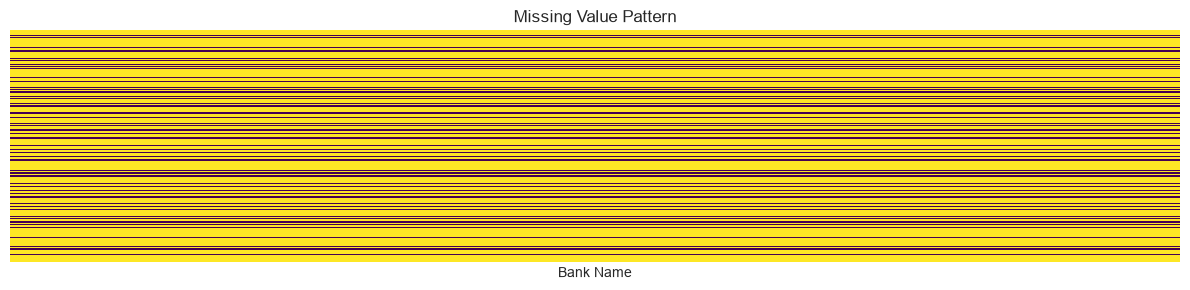

In [19]:
# Missing-value heatmap (only if any)
if df.isna().any().any():
    plt.figure(figsize=(12, 3))
    sns.heatmap(df[df.columns[df.isna().any()]].isna(),
                cbar=False, cmap="viridis", yticklabels=False)
    plt.title("Missing Value Pattern")
    plt.tight_layout(); plt.show()

### Basic Business Information

In [20]:
# 4.1 Headline KPIs
def fmt(x): return f"৳ {x:,.0f}"

kpi = pd.DataFrame({
    "KPI": [
        "Rows (invoice lines)", "Unique Invoices", "Unique Customers",
        "Unique Products", "Unique Sales Reps", "Zones Active",
        "Period Start", "Period End",
        "Total Sales Amount", "Total VAT", "Total Returns",
        "Total Outstanding", "Total Collected",
        "Avg Invoice Value", "Avg Discount %",
        "Gross Margin", "Gross Margin %",
        "Collection Rate %",
    ],
    "Value": [
        f"{len(df):,}",
        f"{df['Invoice No'].nunique():,}",
        f"{df['Customer ID'].nunique():,}",
        f"{df['Barcode'].nunique():,}",
        f"{df['Sales ID'].nunique():,}",
        f"{df['Zone Code'].nunique():,}",
        f"{df['Date'].min():%d-%b-%Y}",
        f"{df['Date'].max():%d-%b-%Y}",
        fmt(df["Sales Amount"].sum()),
        fmt(df["Sales VAT"].sum()),
        fmt(df["Sales Return"].sum()),
        fmt(df["Credited Amount"].sum()),
        fmt(df["Collection Amount"].sum()),
        fmt(df["Invoice Value"].mean()),
        f"{(df['Discount'].sum() / df['Invoice Value'].sum() * 100):.2f}%",
        fmt(df["Gross Margin"].sum()),
        f"{(df['Gross Margin'].sum() / df['Sales Amount'].sum() * 100):.2f}%",
        f"{(df['Collection Amount'].sum() / df['Net Revenue'].sum() * 100):.2f}%",
    ],
})
kpi

,KPI,Value
0,Rows (invoice lines),"19,002"
1,Unique Invoices,"19,002"
2,Unique Customers,264
3,Unique Products,125
4,Unique Sales Reps,13
5,Zones Active,13
6,Period Start,01-Jan-2025
7,Period End,31-Dec-2025
8,Total Sales Amount,"৳ 129,916,305"
9,Total VAT,"৳ 3,804,068"


### Sales Overview

In [21]:
# 5.1 Monthly trend
monthly = (df.groupby(df["Date"].dt.to_period("M"))
             .agg(Revenue=("Sales Amount","sum"),
                  Invoices=("Invoice No","nunique"),
                  Customers=("Customer ID","nunique"),
                  Margin=("Gross Margin","sum"),
                  VAT=("Sales VAT","sum"),
                  Returns=("Sales Return","sum"))
             .reset_index()
             .rename(columns={"Date":"Month"}))
monthly["Month"]  = monthly["Month"].dt.to_timestamp()
monthly["MoM %"]  = monthly["Revenue"].pct_change().mul(100).round(2)
monthly

,Month,Revenue,Invoices,Customers,Margin,VAT,Returns,MoM %
0,2025-01-01,"8,322,662.50",1302,263,"2,222,596.63","236,294.67","103,336.40",NaN
1,2025-02-01,"7,949,277.70",1187,261,"2,161,493.33","232,569.40","113,924.52",-4.49
2,2025-03-01,"17,086,681.92",2493,264,"4,545,896.48","524,206.92","202,142.57",114.95
3,2025-04-01,"15,250,786.38",2256,264,"4,099,823.04","440,502.16","194,850.44",-10.74
4,2025-05-01,"10,651,655.52",1593,263,"2,888,384.77","319,845.31","165,157.29",-30.16
5,2025-06-01,"9,936,833.38",1465,264,"2,649,733.41","294,140.46","102,714.47",-6.71
6,2025-07-01,"10,395,928.32",1519,263,"2,826,831.42","306,333.40","185,434.28",4.62
7,2025-08-01,"9,993,854.51",1496,263,"2,676,883.36","278,103.97","111,418.67",-3.87
8,2025-09-01,"10,851,152.17",1495,263,"2,894,468.17","302,651.72","133,767.81",8.58
9,2025-10-01,"9,094,656.49",1257,220,"2,476,780.68","269,206.65","117,592.36",-16.19


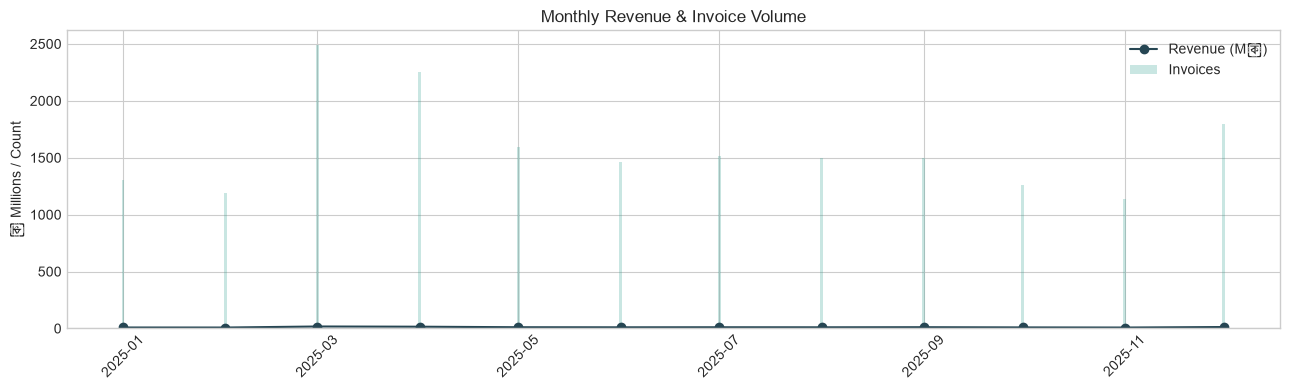

In [22]:
# 5.2 Monthly revenue chart
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(monthly["Month"], monthly["Revenue"]/1e6, marker="o", color="#264653", label="Revenue (M৳)")
ax.bar(monthly["Month"], monthly["Invoices"], alpha=0.25, color="#2a9d8f", label="Invoices")
ax.set_title("Monthly Revenue & Invoice Volume")
ax.set_ylabel("৳ Millions / Count")
ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [23]:
# 5.3 Day-of-week pattern
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow = (df.groupby("Weekday")["Sales Amount"].sum()
         .reindex(order, fill_value=0)
         .to_frame("Revenue"))
dow["Share %"] = (dow["Revenue"] / dow["Revenue"].sum() * 100).round(2)
dow

,Revenue,Share %
Weekday,,
Monday,"17,627,407.11",13.57
Tuesday,"19,922,241.15",15.33
Wednesday,"19,304,790.91",14.86
Thursday,"18,931,352.83",14.57
Friday,"18,259,573.68",14.05
Saturday,"18,051,443.70",13.89
Sunday,"17,819,495.30",13.72


In [24]:
# 5.5 Channel & Invoice Type
pd.concat([
    df.groupby("Sales Channel")["Sales Amount"].sum().rename("Revenue"),
    df.groupby("Sales Channel")["Invoice No"].nunique().rename("Invoices"),
], axis=1).assign(Share_pct=lambda x: (x["Revenue"]/x["Revenue"].sum()*100).round(2))

,Revenue,Invoices,Share_pct
Sales Channel,,,
Direct,"31,883,590.12",4761,24.54
Field,"32,987,923.88",4800,25.39
Online,"32,227,557.72",4736,24.81
Phone,"32,817,232.96",4705,25.26


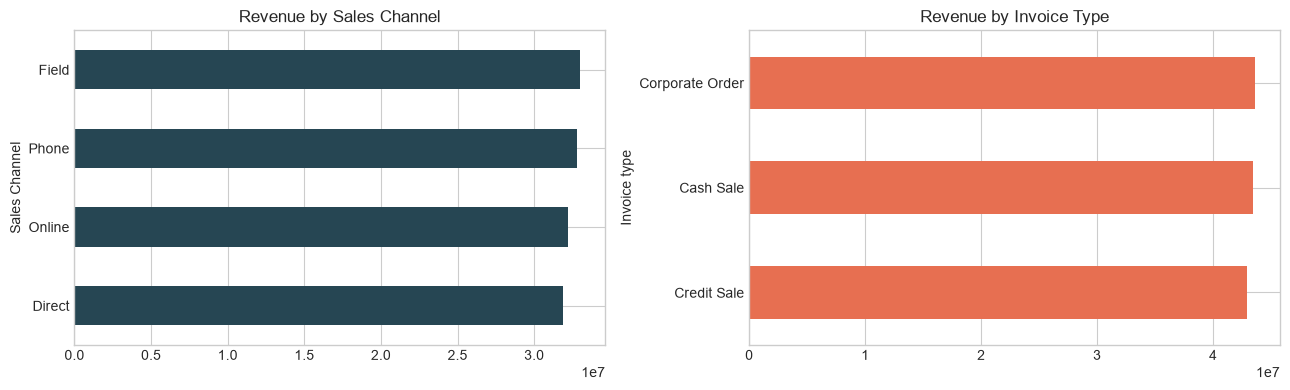

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby("Sales Channel")["Sales Amount"].sum().sort_values().plot.barh(ax=axes[0], color="#264653")
axes[0].set_title("Revenue by Sales Channel")
df.groupby("Invoice type")["Sales Amount"].sum().sort_values().plot.barh(ax=axes[1], color="#e76f51")
axes[1].set_title("Revenue by Invoice Type")
plt.tight_layout(); plt.show()

### Executive Performance

In [26]:
exec_kpi = (df.groupby(["Sales ID", "Sales by", "Sales Zone"])
              .agg(Orders=("Invoice No", "nunique"),
                   Customers=("Customer ID", "nunique"),
                   Revenue=("Sales Amount", "sum"),
                   Margin=("Gross Margin", "sum"),
                   Outstanding=("Credited Amount", "sum"),
                   Returns=("Sales Return", "sum"),
                   Collected=("Collection Amount", "sum"))
              .reset_index())

exec_kpi["Margin %"]     = (exec_kpi["Margin"] / exec_kpi["Revenue"] * 100).round(1)
exec_kpi["Collection %"] = (exec_kpi["Collected"] / exec_kpi["Revenue"] * 100).round(1)
exec_kpi["Avg Ticket"]   = (exec_kpi["Revenue"] / exec_kpi["Orders"]).round(0)
exec_kpi["Revenue Share %"] = (exec_kpi["Revenue"] / exec_kpi["Revenue"].sum() * 100).round(1)

exec_kpi = exec_kpi.sort_values("Revenue", ascending=False).reset_index(drop=True)
exec_kpi

,Sales ID,Sales by,Sales Zone,Orders,Customers,Revenue,Margin,Outstanding,Returns,Collected,Margin %,Collection %,Avg Ticket,Revenue Share %
0,EMP013,Mynuddin Hasan Hridoy,Gulshan,3610,48,"25,897,725.19","7,075,448.13","5,799,722.38","338,799.62","20,532,426.31",27.30,79.30,"7,174.00",19.90
1,EMP011,Karim Ahmed,Dhanmondi,1993,28,"14,110,473.53","3,738,386.26","3,298,661.36","193,156.41","11,031,191.83",26.50,78.20,"7,080.00",10.90
2,EMP006,ATM Noor Hossen Rumel,Demra,1893,26,"12,973,516.39","3,536,637.12","3,003,945.35","196,460.86","10,154,037.22",27.30,78.30,"6,853.00",10.00
3,EMP002,Mohammad Sumon,Badda,1951,27,"11,932,960.79","3,144,971.39","2,717,942.11","178,410.76","9,399,174.40",26.40,78.80,"6,116.00",9.20
4,EMP005,Jahirul Hoque Pranto,Jatrabari,1705,24,"11,760,850.89","3,120,530.10","2,725,626.11","135,639.91","9,231,716.55",26.50,78.50,"6,898.00",9.10
5,EMP004,Sonjoy Hore,Savar,1745,26,"11,650,505.79","3,122,861.77","2,565,636.06","165,965.50","9,251,148.36",26.80,79.40,"6,677.00",9.00
6,EMP007,Sajib Kumar Biswas,Mohammadpur,1537,22,"10,545,297.73","2,785,992.45","2,434,701.53","169,521.44","8,232,661.56",26.40,78.10,"6,861.00",8.10
7,EMP001,Rakibul Islam,Uttara,1498,20,"10,374,756.69","2,777,540.43","2,614,641.86","129,620.97","7,943,072.22",26.80,76.60,"6,926.00",8.00
8,EMP003,Atikur Rahman Razu,Tejgaon,1353,19,"9,300,318.81","2,546,322.63","2,140,924.46","92,527.31","7,343,965.06",27.40,79.00,"6,874.00",7.20
9,EMP012,Imran Hossain,Khilgaon,1307,18,"8,620,298.88","2,329,457.95","1,844,109.27","120,794.90","6,906,178.70",27.00,80.10,"6,595.00",6.60


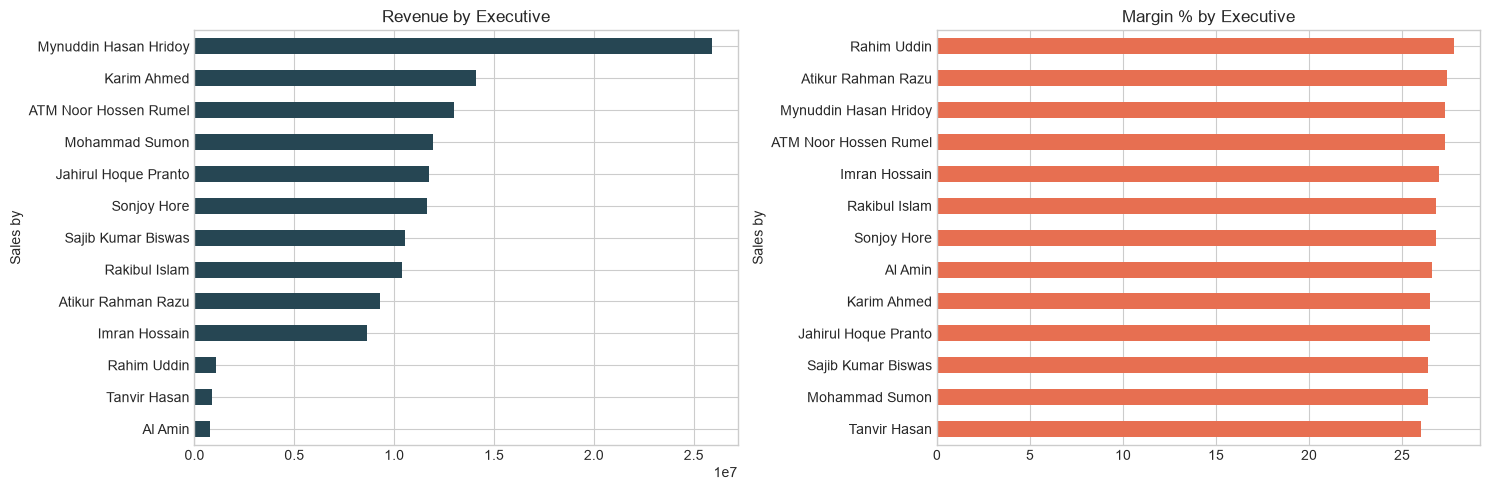

In [27]:
# 6.2 Executive ranking charts
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
exec_kpi.set_index("Sales by")["Revenue"].sort_values().plot.barh(ax=axes[0], color="#264653")
axes[0].set_title("Revenue by Executive")
exec_kpi.set_index("Sales by")["Margin %"].sort_values().plot.barh(ax=axes[1], color="#e76f51")
axes[1].set_title("Margin % by Executive")
plt.tight_layout(); plt.show()

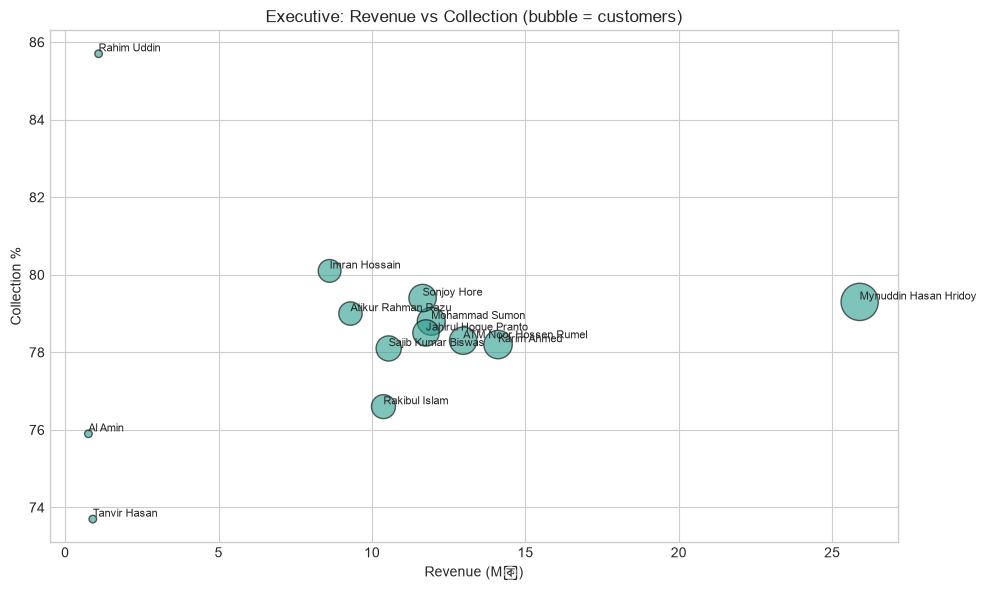

In [28]:
# 6.3 Revenue vs Collection bubble
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(exec_kpi["Revenue"]/1e6, exec_kpi["Collection %"],
           s=exec_kpi["Customers"]*15, alpha=0.6, c="#2a9d8f", edgecolor="k")
for _, r in exec_kpi.iterrows():
    ax.annotate(r["Sales by"], (r["Revenue"]/1e6, r["Collection %"]),
                fontsize=8, ha="left", va="bottom")
ax.set_xlabel("Revenue (M৳)"); ax.set_ylabel("Collection %")
ax.set_title("Executive: Revenue vs Collection (bubble = customers)")
plt.tight_layout(); plt.show()

### Customer Analysis

In [29]:
# 7.1 Customer master analytics
cust = (df.groupby(["Customer ID","Customer Name","Customer Type"])
          .agg(Orders=("Invoice No","nunique"),
               Revenue=("Sales Amount","sum"),
               Margin=("Gross Margin","sum"),
               Outstanding=("Credited Amount","sum"),
               Returns=("Sales Return","sum"),
               LastSale=("Date","max"),
               FirstSale=("Date","min"))
          .reset_index())
cust["LastSale"]  = pd.to_datetime(cust["LastSale"])
cust["FirstSale"] = pd.to_datetime(cust["FirstSale"])
cust["Margin %"]      = (cust["Margin"] / cust["Revenue"] * 100).round(1)
cust["Outstanding %"] = (cust["Outstanding"] / cust["Revenue"] * 100).round(1)
cust["Recency (d)"]   = (df["Date"].max() - cust["LastSale"]).dt.days
cust["Tenure (d)"]    = (df["Date"].max() - cust["FirstSale"]).dt.days
cust = cust.sort_values("Revenue", ascending=False).reset_index(drop=True)

cust.head(15)

,Customer ID,Customer Name,Customer Type,Orders,Revenue,Margin,Outstanding,Returns,LastSale,FirstSale,Margin %,Outstanding %,Recency (d),Tenure (d)
0,CUST0144,M/S Patwary Crockerise Store,Retailer,97,"804,114.03","212,232.81","194,828.61","4,631.18",2025-12-30,2025-01-19,26.40,24.20,1,346
1,CUST0112,M/S Sayed Gift Corner Store,Wholesale,78,"785,916.66","229,050.97","94,373.55","12,571.06",2025-12-31,2025-01-04,29.10,12.00,0,361
2,CUST0092,M/S Adiba Crockeries Store,Wholesale,73,"768,673.66","203,210.63","105,715.28","2,890.83",2025-12-30,2025-01-06,26.40,13.80,1,359
3,CUST0171,M/S Whitney Peters Aluminium,Corporate,83,"747,093.49","209,720.27","162,304.54","1,873.73",2025-12-30,2025-01-01,28.10,21.70,1,364
4,CUST0227,M/S Chandpur Crockeries Store,Online,102,"739,074.61","204,443.11","180,865.53","7,614.96",2025-12-28,2025-01-12,27.70,24.50,3,353
5,CUST0155,M/S Mohammadia Trading Store,Wholesale,87,"738,879.46","191,095.24","308,407.04","10,756.93",2025-12-29,2025-01-02,25.90,41.70,2,363
6,CUST0229,M/S Margaret Hawkins DDS Glass,Retailer,68,"737,411.01","194,113.80","114,310.37","16,449.51",2025-12-30,2025-01-09,26.30,15.50,1,356
7,CUST0162,M/S William Baker Trading,Corporate,85,"735,913.02","204,515.92","150,997.25","4,184.98",2025-12-27,2025-01-18,27.80,20.50,4,347
8,CUST0002,Jarif Enterprise Return,Retailer,84,"735,857.65","211,589.17","171,776.10","7,049.41",2025-12-31,2025-01-01,28.80,23.30,0,364
9,CUST0238,M/S Jewel Crockeries & Servicing Store,Wholesale,83,"727,228.38","200,653.82","145,946.47","5,442.58",2025-12-30,2025-01-01,27.60,20.10,1,364


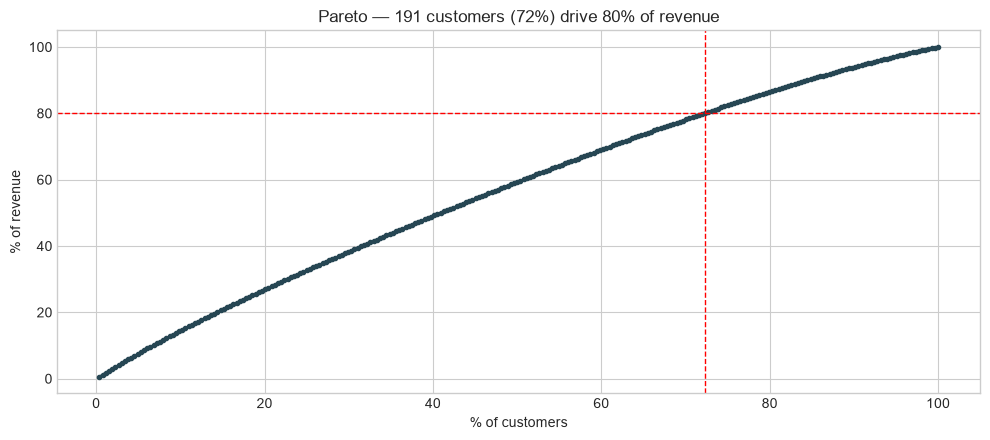

,Metric,Value
0,Customers needed for 80% revenue,191
1,% of total customers,72.3%


In [30]:
# 7.2 Pareto
cust_sorted = cust.sort_values("Revenue", ascending=False).reset_index(drop=True)
cust_sorted["CumRevenue%"] = cust_sorted["Revenue"].cumsum() / cust_sorted["Revenue"].sum() * 100
cust_sorted["CumCust%"]    = (cust_sorted.index + 1) / len(cust_sorted) * 100
n_80 = int((cust_sorted["CumRevenue%"] <= 80).sum() + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cust_sorted["CumCust%"], cust_sorted["CumRevenue%"], marker="o", ms=3, color="#264653")
ax.axhline(80, color="red", ls="--", lw=1)
ax.axvline(n_80/len(cust_sorted)*100, color="red", ls="--", lw=1)
ax.set_xlabel("% of customers"); ax.set_ylabel("% of revenue")
ax.set_title(f"Pareto — {n_80} customers ({n_80/len(cust_sorted)*100:.0f}%) drive 80% of revenue")
plt.tight_layout(); plt.show()

pd.DataFrame({"Metric": ["Customers needed for 80% revenue", "% of total customers"],
              "Value":  [n_80, f"{n_80/len(cust_sorted)*100:.1f}%"]})

In [31]:
# 7.3 RFM segmentation
snap = df["Date"].max() + pd.Timedelta(days=1)
rfm = (df.groupby("Customer ID")
         .agg(R=("Date", lambda s: (snap - s.max()).days),
              F=("Invoice No","nunique"),
              M=("Sales Amount","sum"))
         .reset_index())

rfm["R_Score"] = pd.qcut(rfm["R"].rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["F"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["M"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["RFM_Score"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]

def segment(r):
    if r >= 12: return "Champion"
    if r >= 10: return "Loyal"
    if r >= 8:  return "Potential"
    if r >= 6:  return "At-Risk"
    if r >= 4:  return "Hibernating"
    return "Lost"
rfm["Segment"] = rfm["RFM_Score"].apply(segment)

(rfm.groupby("Segment")
    .agg(Customers=("Customer ID","count"),
         AvgRecency=("R","mean"),
         AvgFrequency=("F","mean"),
         AvgMonetary=("M","mean"))
    .round(1)
    .sort_values("AvgMonetary", ascending=False))

,Customers,AvgRecency,AvgFrequency,AvgMonetary
Segment,,,,
Champion,72,2.20,82.90,"609,238.60"
Loyal,56,4.30,76.40,"524,414.90"
Potential,53,6.70,71.10,"460,934.00"
At-Risk,31,20.50,67.00,"430,562.50"
Hibernating,23,77.60,59.80,"418,834.00"
Lost,29,99.70,52.90,"319,785.20"


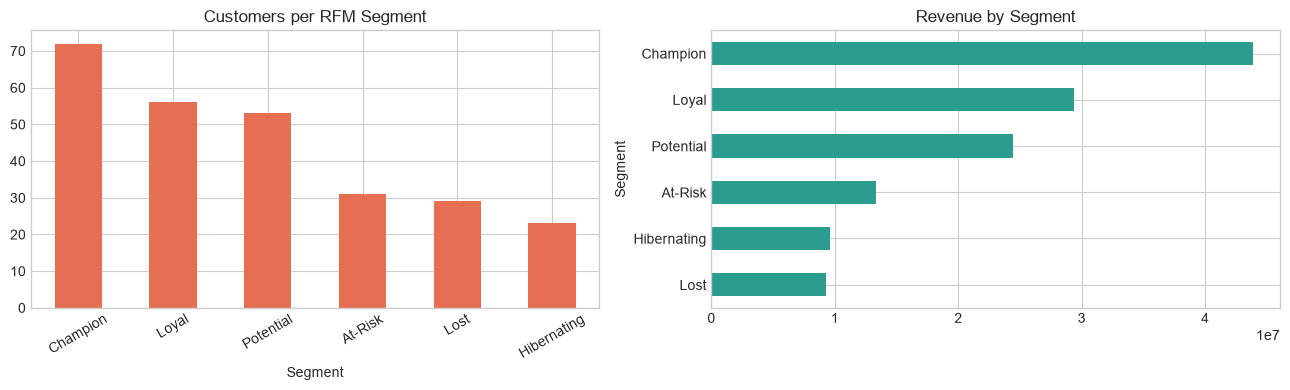

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rfm["Segment"].value_counts().plot.bar(ax=axes[0], color="#e76f51")
axes[0].set_title("Customers per RFM Segment"); axes[0].tick_params(axis="x", rotation=30)
rfm.groupby("Segment")["M"].sum().sort_values().plot.barh(ax=axes[1], color="#2a9d8f")
axes[1].set_title("Revenue by Segment")
plt.tight_layout(); plt.show()

In [33]:
# 7.4 Customer type mix
ct = (df.groupby("Customer Type")
        .agg(Revenue=("Sales Amount","sum"),
             Customers=("Customer ID","nunique"),
             Invoices=("Invoice No","nunique"),
             AvgTicket=("Sales Amount","mean"),
             Outstanding=("Credited Amount","sum")))
ct["Revenue Share %"] = (ct["Revenue"] / ct["Revenue"].sum() * 100).round(1)
ct["Rev/Cust"]        = (ct["Revenue"] / ct["Customers"]).round(0)
ct.sort_values("Revenue", ascending=False)

,Revenue,Customers,Invoices,AvgTicket,Outstanding,Revenue Share %,Rev/Cust
Customer Type,,,,,,,
Retailer,"31,387,434.92",61,4469,"7,023.37","6,967,415.84",24.20,"514,548.00"
Corporate,"28,767,616.81",61,4304,"6,683.93","6,562,965.66",22.10,"471,600.00"
Online,"25,361,270.18",49,3625,"6,996.21","6,171,423.32",19.50,"517,577.00"
Wholesale,"25,078,125.96",50,3634,"6,900.97","5,663,325.60",19.30,"501,563.00"
Dealer,"19,321,856.81",43,2970,"6,505.68","4,401,684.05",14.90,"449,346.00"


In [34]:
# 7.5 Churn signal
churn = rfm[rfm["R"] > 90].copy()
pd.DataFrame({
    "Metric": ["Customers inactive >90 days",
               "% of customer base",
               "Revenue at risk (৳)",
               "Revenue at risk %"],
    "Value":  [len(churn),
               f"{len(churn)/len(rfm)*100:.1f}%",
               f"৳ {churn['M'].sum():,.0f}",
               f"{churn['M'].sum()/rfm['M'].sum()*100:.1f}%"],
})

,Metric,Value
0,Customers inactive >90 days,53
1,% of customer base,20.1%
2,Revenue at risk (৳),"৳ 20,179,615"
3,Revenue at risk %,15.5%


### Zone Analysis

In [35]:
zone = (df.groupby(["Zone Code","Sales Zone"])
          .agg(Orders=("Invoice No","nunique"),
               Customers=("Customer ID","nunique"),
               Revenue=("Sales Amount","sum"),
               Margin=("Gross Margin","sum"),
               Outstanding=("Credited Amount","sum"),
               Returns=("Sales Return","sum"))
          .reset_index())
zone["Margin %"]        = (zone["Margin"] / zone["Revenue"] * 100).round(1)
zone["Revenue Share %"] = (zone["Revenue"] / zone["Revenue"].sum() * 100).round(1)
zone = zone.sort_values("Revenue", ascending=False).reset_index(drop=True)
zone

,Zone Code,Sales Zone,Orders,Customers,Revenue,Margin,Outstanding,Returns,Margin %,Revenue Share %
0,ZON013,Gulshan,3610,48,"25,897,725.19","7,075,448.13","5,799,722.38","338,799.62",27.30,19.90
1,ZON011,Dhanmondi,1993,28,"14,110,473.53","3,738,386.26","3,298,661.36","193,156.41",26.50,10.90
2,ZON006,Demra,1893,26,"12,973,516.39","3,536,637.12","3,003,945.35","196,460.86",27.30,10.00
3,ZON002,Badda,1951,27,"11,932,960.79","3,144,971.39","2,717,942.11","178,410.76",26.40,9.20
4,ZON005,Jatrabari,1705,24,"11,760,850.89","3,120,530.10","2,725,626.11","135,639.91",26.50,9.10
5,ZON004,Savar,1745,26,"11,650,505.79","3,122,861.77","2,565,636.06","165,965.50",26.80,9.00
6,ZON007,Mohammadpur,1537,22,"10,545,297.73","2,785,992.45","2,434,701.53","169,521.44",26.40,8.10
7,ZON001,Uttara,1498,20,"10,374,756.69","2,777,540.43","2,614,641.86","129,620.97",26.80,8.00
8,ZON003,Tejgaon,1353,19,"9,300,318.81","2,546,322.63","2,140,924.46","92,527.31",27.40,7.20
9,ZON012,Khilgaon,1307,18,"8,620,298.88","2,329,457.95","1,844,109.27","120,794.90",27.00,6.60


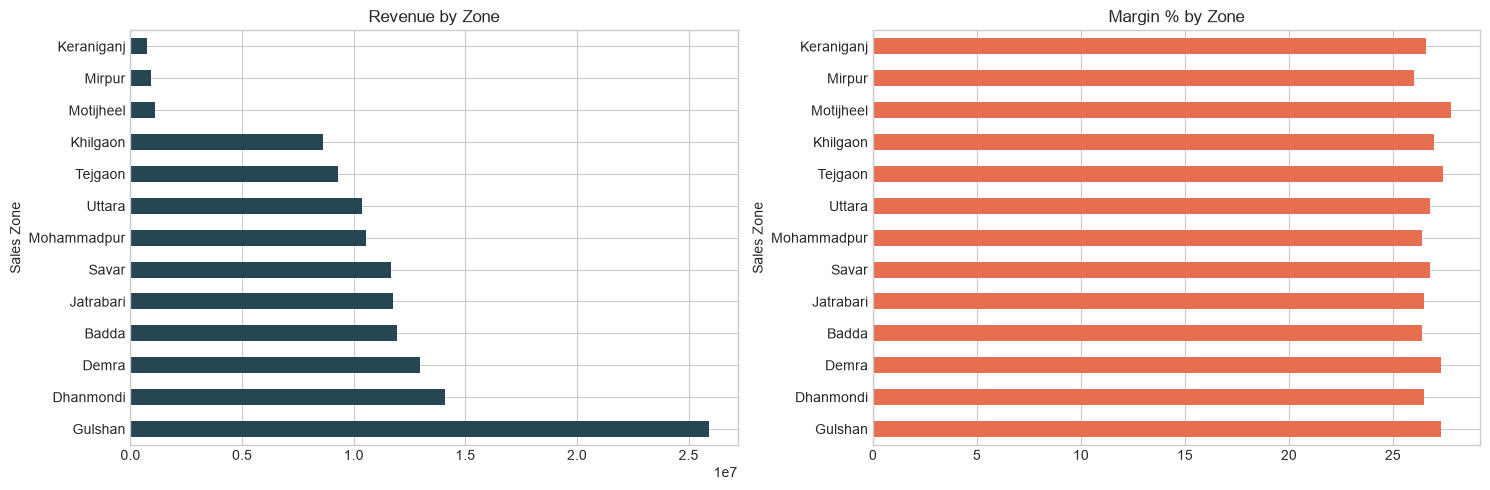

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
zone.set_index("Sales Zone")["Revenue"].plot.barh(ax=axes[0], color="#264653")
axes[0].set_title("Revenue by Zone")
zone.set_index("Sales Zone")["Margin %"].plot.barh(ax=axes[1], color="#e76f51")
axes[1].set_title("Margin % by Zone")
plt.tight_layout(); plt.show()

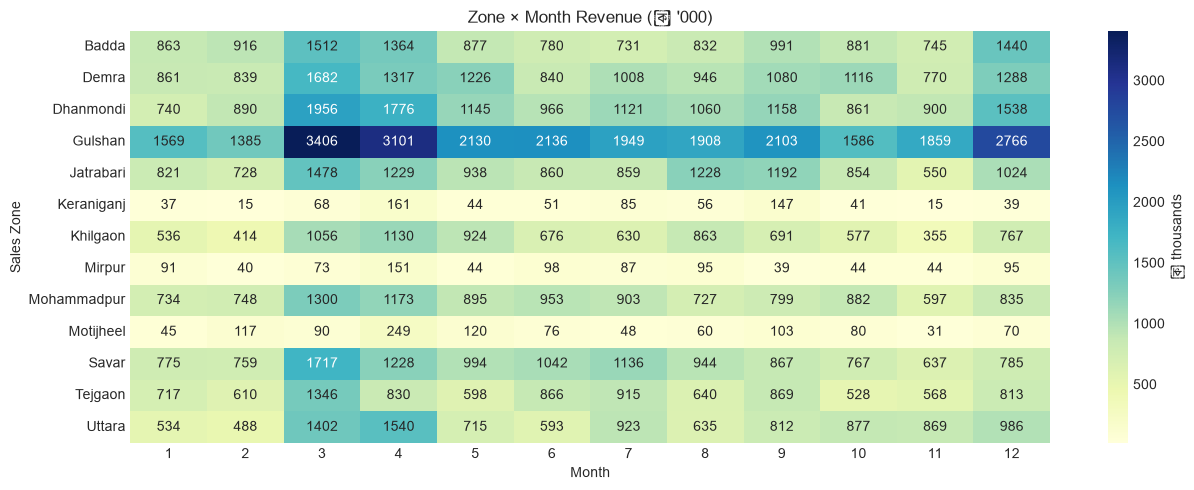

In [37]:
# 8.1 Zone × Month heatmap
pivot = df.pivot_table(index="Sales Zone", columns="Month",
                       values="Sales Amount", aggfunc="sum", fill_value=0)
plt.figure(figsize=(13, 5))
sns.heatmap(pivot/1e3, cmap="YlGnBu", fmt=".0f", annot=True,
            cbar_kws={"label":"৳ thousands"})
plt.title("Zone × Month Revenue (৳ '000)")
plt.tight_layout(); plt.show()

### Product Analysis

In [38]:
prod = (df.groupby(["Barcode","Product Name","Product Category"])
          .agg(Units=("Invoice Value","count"),
               Revenue=("Sales Amount","sum"),
               Cost=("Purchase Value","sum"),
               Margin=("Gross Margin","sum"),
               Returns=("Sales Return","sum"),
               Orders=("Invoice No","nunique"))
          .reset_index())
prod["Margin %"] = (prod["Margin"] / prod["Revenue"] * 100).round(1)
prod["Return %"] = (prod["Returns"] / prod["Revenue"] * 100).round(2)
prod = prod.sort_values("Revenue", ascending=False).reset_index(drop=True)
prod.head(10)

,Barcode,Product Name,Product Category,Units,Revenue,Cost,Margin,Returns,Orders,Margin %,Return %
0,8844731952676,Steel Rack 4,Hardware,175,"2,248,361.00","1,510,374.06","737,986.94","22,419.74",175,32.80,1.00
1,8873958187345,Blender 5,Electronics,150,"2,195,432.76","1,599,092.85","596,339.91","36,724.19",150,27.20,1.67
2,8817991656753,Dinner Set 4,Tableware,145,"2,139,614.40","1,434,494.74","705,119.66","55,547.29",145,33.00,2.60
3,8850608951738,Non-stick Pan 1,Cookware,173,"2,078,618.34","1,671,595.44","407,022.90","12,646.69",173,19.60,0.61
4,8858443472984,Bowl Set 4,Tableware,144,"2,068,958.53","1,332,731.53","736,227.00","39,228.33",144,35.60,1.90
5,8844058579637,Plate Set 1,Tableware,147,"1,931,227.18","1,259,376.45","671,850.73","33,570.13",147,34.80,1.74
6,8874776294029,Photo Frame 1,Gift Items,172,"1,905,155.03","1,276,868.52","628,286.51","49,878.89",172,33.00,2.62
7,8889953027759,Electric Kettle 1,Electronics,162,"1,899,189.07","1,238,348.70","660,840.37","14,628.34",162,34.80,0.77
8,8849488434329,Tool Kit 5,Hardware,148,"1,895,569.99","1,386,332.01","509,237.98","31,089.52",148,26.90,1.64
9,8843841208003,Frying Pan 5,Cookware,134,"1,834,935.80","1,213,756.88","621,178.92","13,701.28",134,33.90,0.75


In [39]:
# 9.2 Category overview
cat = (df.groupby("Product Category")
         .agg(Revenue=("Sales Amount","sum"),
              Units=("Invoice Value","count"),
              Margin=("Gross Margin","sum"),
              Products=("Barcode","nunique")))
cat["Margin %"] = (cat["Margin"] / cat["Revenue"] * 100).round(1)
cat["Share %"]  = (cat["Revenue"] / cat["Revenue"].sum() * 100).round(1)
cat.sort_values("Revenue", ascending=False)

,Revenue,Units,Margin,Products,Margin %,Share %
Product Category,,,,,,
Hardware,"27,987,053.86",3808,"6,831,249.95",25,24.40,21.50
Tableware,"27,357,861.11",3804,"7,735,064.48",25,28.30,21.10
Electronics,"26,021,454.04",3733,"7,006,611.27",25,26.90,20.00
Gift Items,"25,847,965.12",3780,"6,965,374.12",25,26.90,19.90
Cookware,"22,701,970.55",3877,"6,378,881.21",25,28.10,17.50


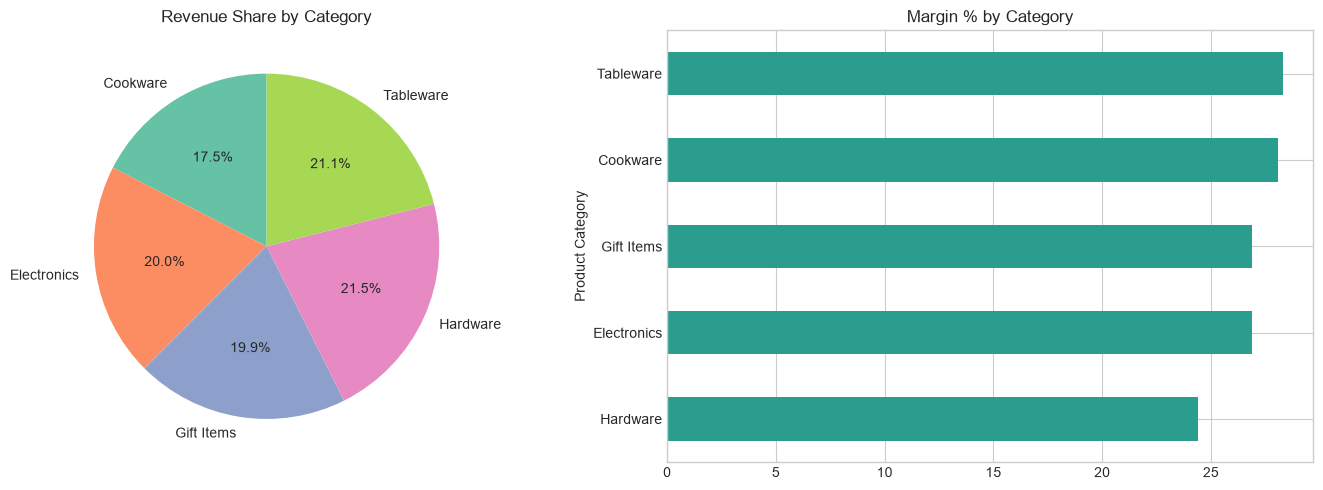

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cat["Revenue"].plot.pie(ax=axes[0], autopct="%1.1f%%", startangle=90)
axes[0].set_ylabel(""); axes[0].set_title("Revenue Share by Category")
cat["Margin %"].sort_values().plot.barh(ax=axes[1], color="#2a9d8f")
axes[1].set_title("Margin % by Category")
plt.tight_layout(); plt.show()

In [41]:
# 9.3 ABC classification
prod_abc = prod.sort_values("Revenue", ascending=False).reset_index(drop=True).copy()
prod_abc["Cum%"] = prod_abc["Revenue"].cumsum() / prod_abc["Revenue"].sum() * 100
prod_abc["ABC"]  = np.where(prod_abc["Cum%"] <= 70, "A",
                     np.where(prod_abc["Cum%"] <= 90, "B", "C"))
(prod_abc.groupby("ABC")
    .agg(Products=("Barcode","count"),
         Revenue=("Revenue","sum"))
    .assign(Share_pct=lambda x: (x["Revenue"]/x["Revenue"].sum()*100).round(1)))

,Products,Revenue,Share_pct
ABC,,,
A,58,"90,822,458.43",69.90
B,30,"26,068,725.89",20.10
C,37,"13,025,120.36",10.00


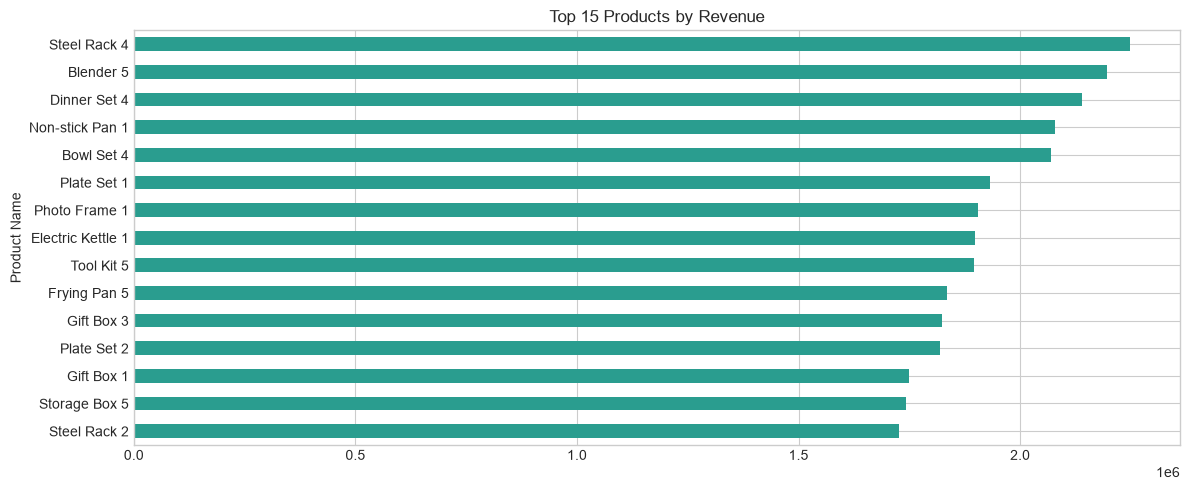

In [42]:
# 9.4 Top products treemap (optional if squarify installed)
try:
    import squarify
    top20 = prod.nlargest(20, "Revenue")
    plt.figure(figsize=(13, 6))
    squarify.plot(sizes=top20["Revenue"],
                  label=top20["Product Name"].str[:18],
                  alpha=0.75, color=sns.color_palette("Set3", 20))
    plt.title("Top 20 Products by Revenue")
    plt.axis("off"); plt.tight_layout(); plt.show()
except ImportError:
    plt.figure(figsize=(12, 5))
    prod.nlargest(15, "Revenue").set_index("Product Name")["Revenue"].sort_values().plot.barh(color="#2a9d8f")
    plt.title("Top 15 Products by Revenue")
    plt.tight_layout(); plt.show()

### Bank Analysis

In [43]:
bank = (df[df["Bank Name"].notna()]
          .groupby("Bank Name")
          .agg(Transactions=("Invoice No","nunique"),
               Revenue=("Sales Amount","sum"),
               AvgTicket=("Sales Amount","mean"),
               Outstanding=("Credited Amount","sum"))
          .round(0))
bank["Share %"] = (bank["Revenue"] / bank["Revenue"].sum() * 100).round(2)
bank.sort_values("Revenue", ascending=False)

,Transactions,Revenue,AvgTicket,Outstanding,Share %
Bank Name,,,,,
City Bank,808,"5,859,684.00","7,252.00","1,346,803.00",15.38
Sonali Bank,838,"5,764,361.00","6,879.00","1,314,960.00",15.13
BRAC Bank,814,"5,549,362.00","6,817.00","1,306,663.00",14.57
Dutch-Bangla Bank,817,"5,341,159.00","6,538.00","1,253,368.00",14.02
Islami Bank,806,"5,245,804.00","6,508.00","1,307,270.00",13.77
Agrani Bank,788,"5,183,362.00","6,578.00","1,171,467.00",13.61
Eastern Bank,808,"5,146,736.00","6,370.00","1,337,715.00",13.51


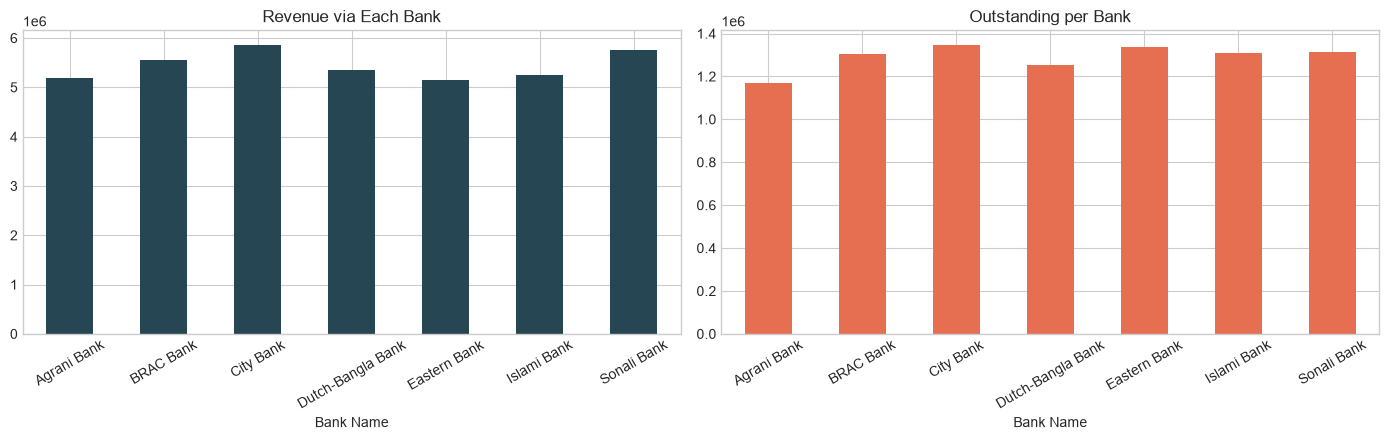

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bank["Revenue"].plot.bar(ax=axes[0], color="#264653")
axes[0].set_title("Revenue via Each Bank"); axes[0].tick_params(axis="x", rotation=30)
bank["Outstanding"].plot.bar(ax=axes[1], color="#e76f51")
axes[1].set_title("Outstanding per Bank"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### Payment Method Analysis

In [45]:
pay = (df.groupby("Payment Method")
         .agg(Transactions=("Invoice No","nunique"),
              Revenue=("Sales Amount","sum"),
              Outstanding=("Credited Amount","sum"),
              Returns=("Sales Return","sum"))
         .round(0))
pay["Revenue Share %"] = (pay["Revenue"] / pay["Revenue"].sum() * 100).round(1)
pay["Collection %"]    = ((pay["Revenue"] - pay["Outstanding"]) / pay["Revenue"] * 100).round(1)
pay.sort_values("Revenue", ascending=False)

,Transactions,Revenue,Outstanding,Returns,Revenue Share %,Collection %
Payment Method,,,,,,
Cash,8578,"58,674,725.00","13,244,574.00","795,690.00",45.20,77.40
Bkash,2835,"19,639,214.00","4,368,345.00","308,750.00",15.10,77.80
Bank,2806,"18,913,808.00","4,519,781.00","241,267.00",14.60,76.10
Nagad,1910,"13,511,897.00","3,115,650.00","159,974.00",10.40,76.90
Online,1885,"12,918,359.00","3,084,496.00","173,084.00",9.90,76.10
Cheque,988,"6,258,301.00","1,433,969.00","76,216.00",4.80,77.10


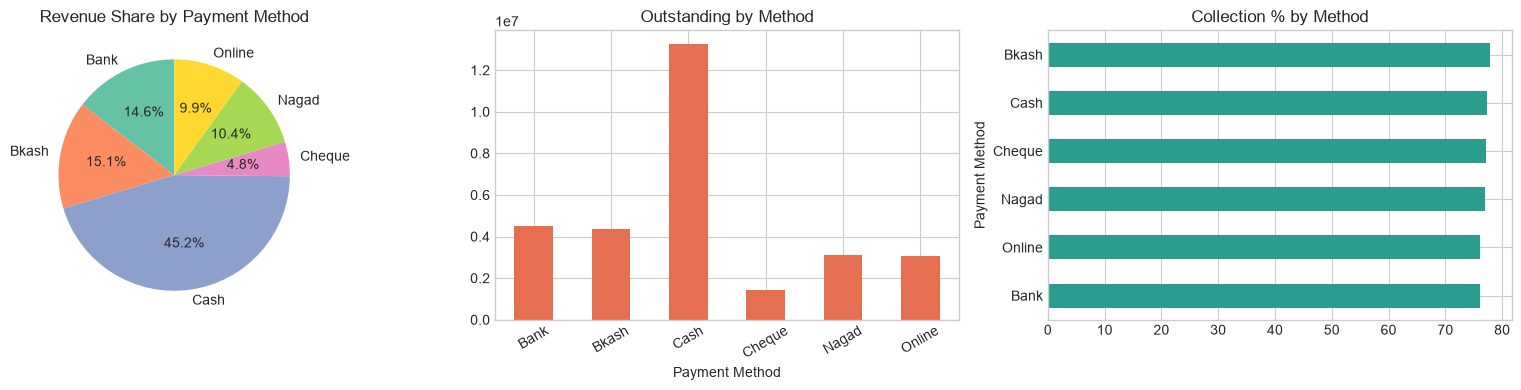

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pay["Revenue"].plot.pie(ax=axes[0], autopct="%1.1f%%", startangle=90)
axes[0].set_ylabel(""); axes[0].set_title("Revenue Share by Payment Method")
pay["Outstanding"].plot.bar(ax=axes[1], color="#e76f51")
axes[1].set_title("Outstanding by Method"); axes[1].tick_params(axis="x", rotation=30)
pay["Collection %"].sort_values().plot.barh(ax=axes[2], color="#2a9d8f")
axes[2].set_title("Collection % by Method")
plt.tight_layout(); plt.show()

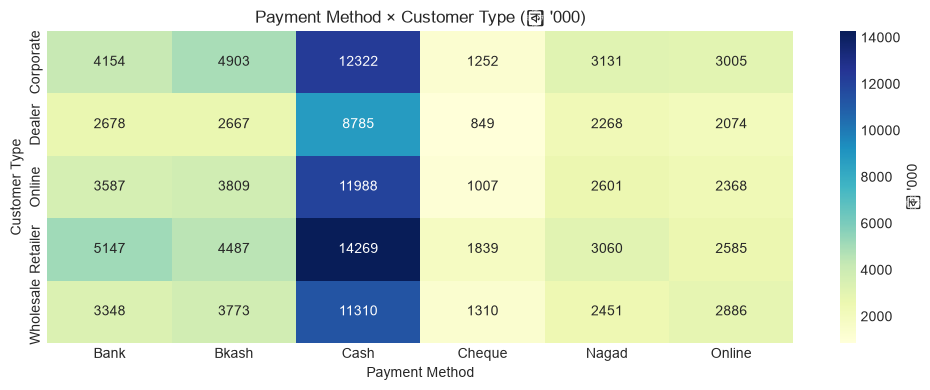

Payment Method,Bank,Bkash,Cash,Cheque,Nagad,Online
Customer Type,,,,,,
Corporate,"4,154,461.00","4,902,610.00","12,321,940.00","1,252,429.00","3,130,825.00","3,005,351.00"
Dealer,"2,678,020.00","2,667,133.00","8,785,155.00","849,210.00","2,268,446.00","2,073,893.00"
Online,"3,586,937.00","3,809,070.00","11,988,484.00","1,007,249.00","2,601,329.00","2,368,202.00"
Retailer,"5,146,805.00","4,486,963.00","14,269,429.00","1,839,012.00","3,060,207.00","2,585,019.00"
Wholesale,"3,347,586.00","3,773,438.00","11,309,718.00","1,310,401.00","2,451,091.00","2,885,894.00"


In [47]:
# Cross: Payment × Customer Type
pivot = df.pivot_table(index="Customer Type", columns="Payment Method",
                       values="Sales Amount", aggfunc="sum", fill_value=0)
plt.figure(figsize=(10, 4))
sns.heatmap(pivot/1e3, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label":"৳ '000"})
plt.title("Payment Method × Customer Type (৳ '000)")
plt.tight_layout(); plt.show()

(pivot.round(0))

### Financial Overview

In [48]:
# 12.1 Revenue bridge
tot_invoice = df["Invoice Value"].sum()
tot_disc    = df["Discount"].sum()
tot_sales   = df["Sales Amount"].sum()
tot_vat     = df["Sales VAT"].sum()
tot_ret     = df["Sales Return"].sum()
tot_cred    = df["Credited Amount"].sum()
tot_coll    = tot_sales + tot_vat - tot_ret - tot_cred

bridge = pd.DataFrame({
    "Component": ["Invoice Value","– Discount","= Sales Amount",
                  "+ VAT","– Returns","– Outstanding","= Collected"],
    "Amount (৳)": [tot_invoice, -tot_disc, tot_sales,
                   tot_vat, -tot_ret, -tot_cred, tot_coll],
})
bridge["% of Invoice"] = (bridge["Amount (৳)"] / tot_invoice * 100).round(1)
bridge

,Component,Amount (৳),% of Invoice
0,Invoice Value,"135,996,658.03",100.00
1,– Discount,"-6,080,353.35",-4.50
2,= Sales Amount,"129,916,304.68",95.50
3,+ VAT,"3,804,067.81",2.80
4,– Returns,"-1,754,980.59",-1.30
5,– Outstanding,"-29,766,814.47",-21.90
6,= Collected,"102,198,577.43",75.10


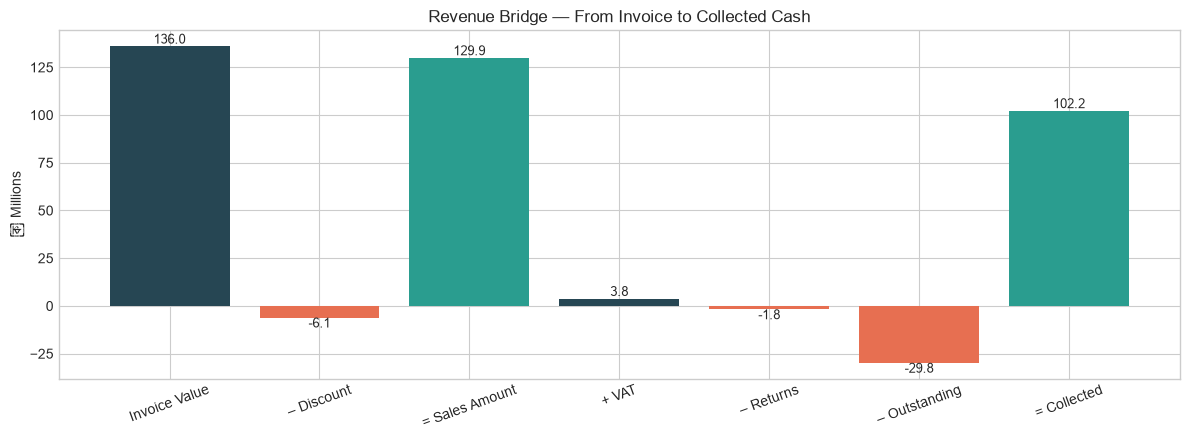

In [49]:
fig, ax = plt.subplots(figsize=(12, 4.5))
colors = ["#264653","#e76f51","#2a9d8f","#264653","#e76f51","#e76f51","#2a9d8f"]
ax.bar(bridge["Component"], bridge["Amount (৳)"]/1e6, color=colors)
ax.set_ylabel("৳ Millions")
ax.set_title("Revenue Bridge — From Invoice to Collected Cash")
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(bridge["Amount (৳)"]):
    ax.text(i, v/1e6, f"{v/1e6:.1f}", ha="center",
            va="bottom" if v > 0 else "top", fontsize=9)
plt.tight_layout(); plt.show()

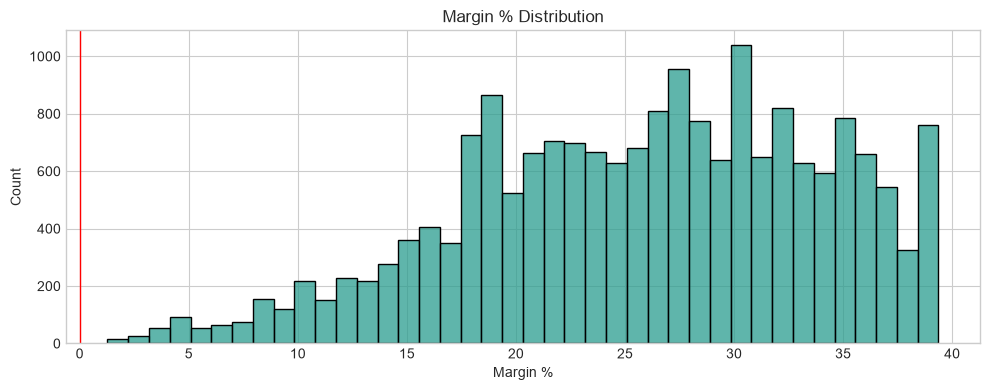

,Margin %
count,"19,002.00"
mean,25.82
std,8.08
min,1.27
25%,19.77
50%,26.67
75%,32.02
max,39.37


In [50]:
# 12.2 Margin distribution
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df["Margin %"].clip(-50, 100), bins=40, color="#2a9d8f", ax=ax)
ax.axvline(0, color="red", lw=1)
ax.set_title("Margin % Distribution")
plt.tight_layout(); plt.show()

df["Margin %"].describe().round(2).to_frame()

In [51]:
# 12.3 Discount impact on margin
df["Discount Bucket"] = pd.cut(df["Discount %"],
                               bins=[-1, 0.001, 5, 10, 15, 200],
                               labels=["0%","0–5%","5–10%","10–15%",">15%"])
disc_margin = (df.groupby("Discount Bucket", observed=True)
                 .agg(AvgMargin=("Margin %","mean"),
                      Invoices=("Invoice No","count"),
                      Revenue=("Sales Amount","sum")))
disc_margin["Revenue Share %"] = (disc_margin["Revenue"] / disc_margin["Revenue"].sum() * 100).round(1)
disc_margin.round(2)

,AvgMargin,Invoices,Revenue,Revenue Share %
Discount Bucket,,,,
0%,29.33,8409,"60,898,626.86",46.90
0–5%,26.65,4229,"28,011,904.33",21.60
5–10%,22.47,4265,"28,111,045.58",21.60
10–15%,16.91,2099,"12,894,727.91",9.90


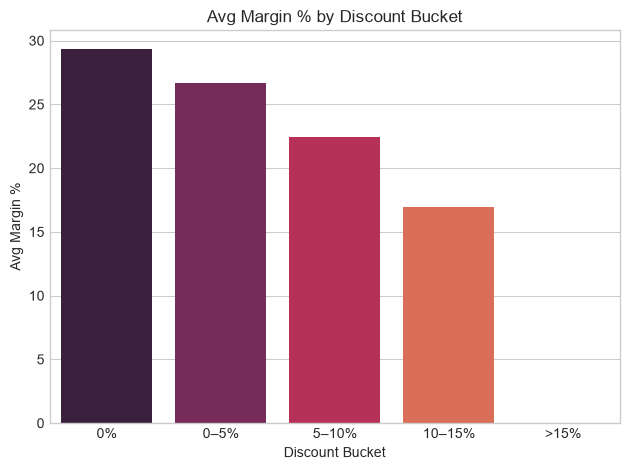

In [52]:
sns.barplot(x=disc_margin.index, y="AvgMargin", data=disc_margin.reset_index(),
            palette="rocket")
plt.title("Avg Margin % by Discount Bucket")
plt.ylabel("Avg Margin %")
plt.tight_layout(); plt.show()

In [53]:
# 12.4 Monthly collection vs outstanding
coll = (df.groupby(df["Date"].dt.to_period("M"))
          .agg(Sales=("Sales Amount","sum"),
               Collected=("Collection Amount","sum"),
               Outstanding=("Credited Amount","sum"))
          .reset_index().rename(columns={"Date":"Month"}))
coll["Month"]        = coll["Month"].dt.to_timestamp()
coll["Collection %"] = (coll["Collected"] / coll["Sales"] * 100).round(1)
coll

,Month,Sales,Collected,Outstanding,Collection %
0,2025-01-01,"8,322,662.50","6,381,253.26","2,074,367.51",76.70
1,2025-02-01,"7,949,277.70","6,066,475.51","2,001,447.07",76.30
2,2025-03-01,"17,086,681.92","13,690,851.87","3,717,894.40",80.10
3,2025-04-01,"15,250,786.38","11,786,088.89","3,710,349.21",77.30
4,2025-05-01,"10,651,655.52","8,318,011.54","2,488,332.00",78.10
5,2025-06-01,"9,936,833.38","7,948,300.46","2,179,958.91",80.00
6,2025-07-01,"10,395,928.32","8,108,482.94","2,408,344.50",78.00
7,2025-08-01,"9,993,854.51","7,820,558.24","2,339,981.57",78.30
8,2025-09-01,"10,851,152.17","8,553,733.23","2,466,302.85",78.80
9,2025-10-01,"9,094,656.49","7,241,564.86","2,004,705.92",79.60


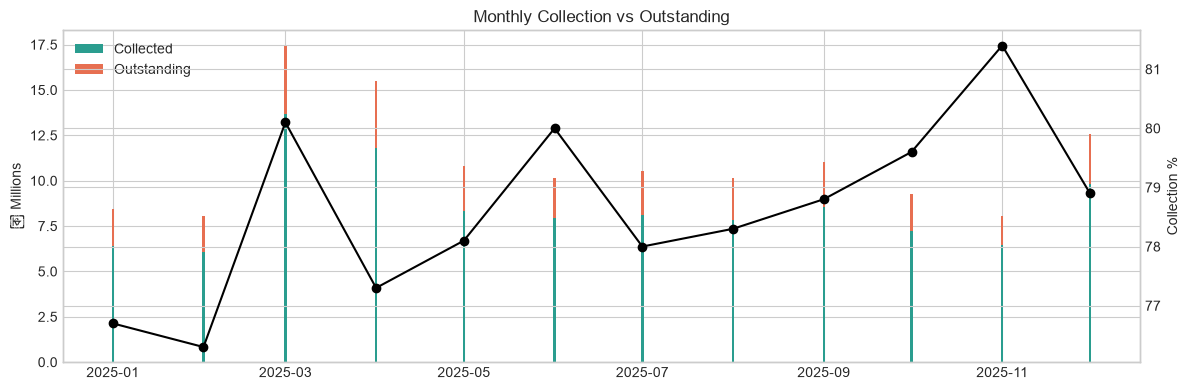

In [54]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(coll["Month"], coll["Collected"]/1e6, label="Collected", color="#2a9d8f")
ax.bar(coll["Month"], coll["Outstanding"]/1e6, bottom=coll["Collected"]/1e6,
       label="Outstanding", color="#e76f51")
ax2 = ax.twinx()
ax2.plot(coll["Month"], coll["Collection %"], color="black", marker="o", label="Collection %")
ax2.set_ylabel("Collection %")
ax.set_ylabel("৳ Millions")
ax.set_title("Monthly Collection vs Outstanding")
ax.legend(loc="upper left")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

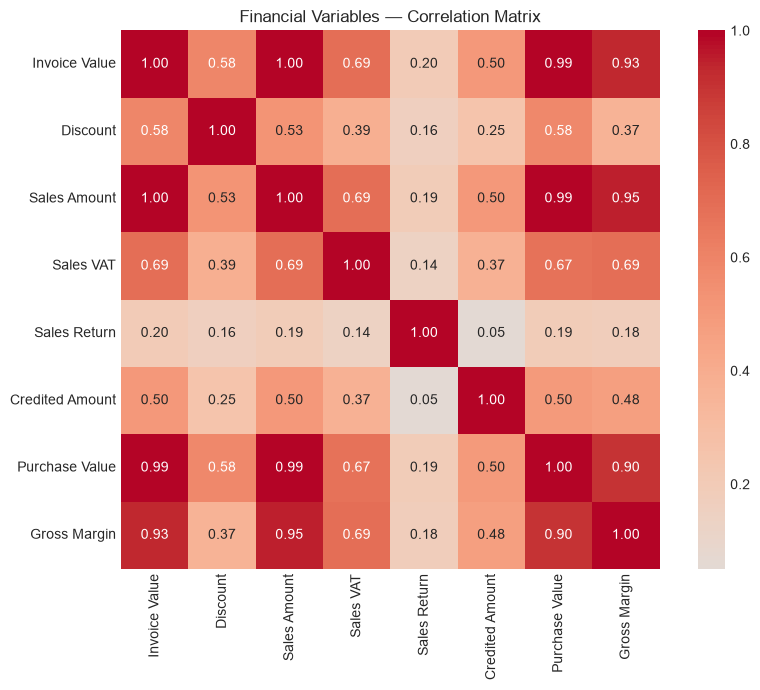

In [55]:
# 12.5 Financial correlation matrix
fin_cols = ["Invoice Value","Discount","Sales Amount","Sales VAT",
            "Sales Return","Credited Amount","Purchase Value","Gross Margin"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[fin_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True)
plt.title("Financial Variables — Correlation Matrix")
plt.tight_layout(); plt.show()

### Executive Summary DataFrame

In [56]:
summary = pd.DataFrame({
    "Section":  ["Period","Volume","Customers","Products",
                 "Sales Amount","Gross Margin","Outstanding","Returns",
                 "Collection Rate",
                 "Top Category","Top Zone","Top Executive","Churn Risk"],
    "Value": [
        f"{df['Date'].min():%d-%b-%Y} → {df['Date'].max():%d-%b-%Y}",
        f"{len(df):,} rows · {df['Invoice No'].nunique():,} invoices",
        f"{df['Customer ID'].nunique()} active",
        f"{df['Barcode'].nunique()} SKUs",
        f"৳ {df['Sales Amount'].sum():,.0f}",
        f"৳ {df['Gross Margin'].sum():,.0f} ({df['Gross Margin'].sum()/df['Sales Amount'].sum()*100:.1f}%)",
        f"৳ {df['Credited Amount'].sum():,.0f}",
        f"৳ {df['Sales Return'].sum():,.0f}",
        f"{df['Collection Amount'].sum()/df['Net Revenue'].sum()*100:.1f}%",
        f"{cat.index[0]} ({cat['Share %'].iloc[0]}%)",
        f"{zone.iloc[0]['Sales Zone']} ({zone.iloc[0]['Revenue Share %']}%)",
        exec_kpi.iloc[0]["Sales by"],
        f"{len(churn)} customers · ৳{churn['M'].sum():,.0f}",
    ],
})
summary

,Section,Value
0,Period,01-Jan-2025 → 31-Dec-2025
1,Volume,"19,002 rows · 19,002 invoices"
2,Customers,264 active
3,Products,125 SKUs
4,Sales Amount,"৳ 129,916,305"
5,Gross Margin,"৳ 34,917,181 (26.9%)"
6,Outstanding,"৳ 29,766,814"
7,Returns,"৳ 1,754,981"
8,Collection Rate,77.4%
9,Top Category,Cookware (17.5%)
